In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

alpha = 0.99
T = 0.1
E_rho = 0.5

data_dir = "loss_data"
filenames = [
    "L_diffus_eq.txt",
    "L_xmom_eq.txt",
    "L_ymom_eq.txt",
    "L_n.txt",
    "L_low_bc.txt"
]

loss_names = ["Diffus Eq", "X-Mom Eq", "Y-Mom Eq", "Data (n)", "Low BC"]

def load_loss_data(directory, files):
    data_list = []
    min_len = float('inf')
    for f in files:
        filepath = os.path.join(directory, f)
        if os.path.exists(filepath):
            data = np.loadtxt(filepath, usecols=1)
            data_list.append(data)
            if len(data) < min_len:
                min_len = len(data)
        else:
            return None

    return np.array([d[:min_len] for d in data_list])

losses_history = load_loss_data(data_dir, filenames)

if losses_history is None:
    num_steps = 1000
    m = len(loss_names)
    losses_history = np.zeros((m, num_steps))
    for i in range(m):
        decay_rate = np.random.uniform(0.001, 0.01)
        base_loss = np.exp(-decay_rate * np.arange(num_steps)) * (i+1)*10
        noise = np.random.normal(0, base_loss * 0.05)
        losses_history[i] = base_loss + noise

num_components = losses_history.shape[0]
num_iterations = losses_history.shape[1]

In [ ]:
lambdas = np.ones((num_components, num_iterations))

def calc_lambda_bal(L_t, L_t_prime, temp, m):
    ratio = L_t / (temp * L_t_prime + 1e-8)
    ratio_shifted = ratio - np.max(ratio)
    exp_vals = np.exp(ratio_shifted)
    softmax_vals = exp_vals / np.sum(exp_vals)
    return m * softmax_vals

for t in range(1, num_iterations):
    L_t = losses_history[:, t]
    L_t_minus_1 = losses_history[:, t-1]
    L_0 = losses_history[:, 0]

    lam_bal_t_0 = calc_lambda_bal(L_t, L_0, T, num_components)
    lam_bal_t_t1 = calc_lambda_bal(L_t, L_t_minus_1, T, num_components)

    rho = np.random.binomial(1, E_rho)
    lam_hist = rho * lambdas[:, t-1] + (1 - rho) * lam_bal_t_0
    lambdas[:, t] = alpha * lam_hist + (1 - alpha) * lam_bal_t_t1

<>:6: SyntaxWarning: invalid escape sequence '\l'
<>:8: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:6: SyntaxWarning: invalid escape sequence '\l'
<>:8: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_4642/3693464675.py:6: SyntaxWarning: invalid escape sequence '\l'
  axes[0].set_title('Изменение весовых коэффициентов $\lambda_i(t)$')
/tmp/ipykernel_4642/3693464675.py:8: SyntaxWarning: invalid escape sequence '\l'
  axes[0].set_ylabel('Значение $\lambda$')
/tmp/ipykernel_4642/3693464675.py:24: SyntaxWarning: invalid escape sequence '\l'
  axes[2].set_title('Взвешенные компоненты Loss ($\lambda_i(t) \cdot \mathcal{L}_i(t)$)')


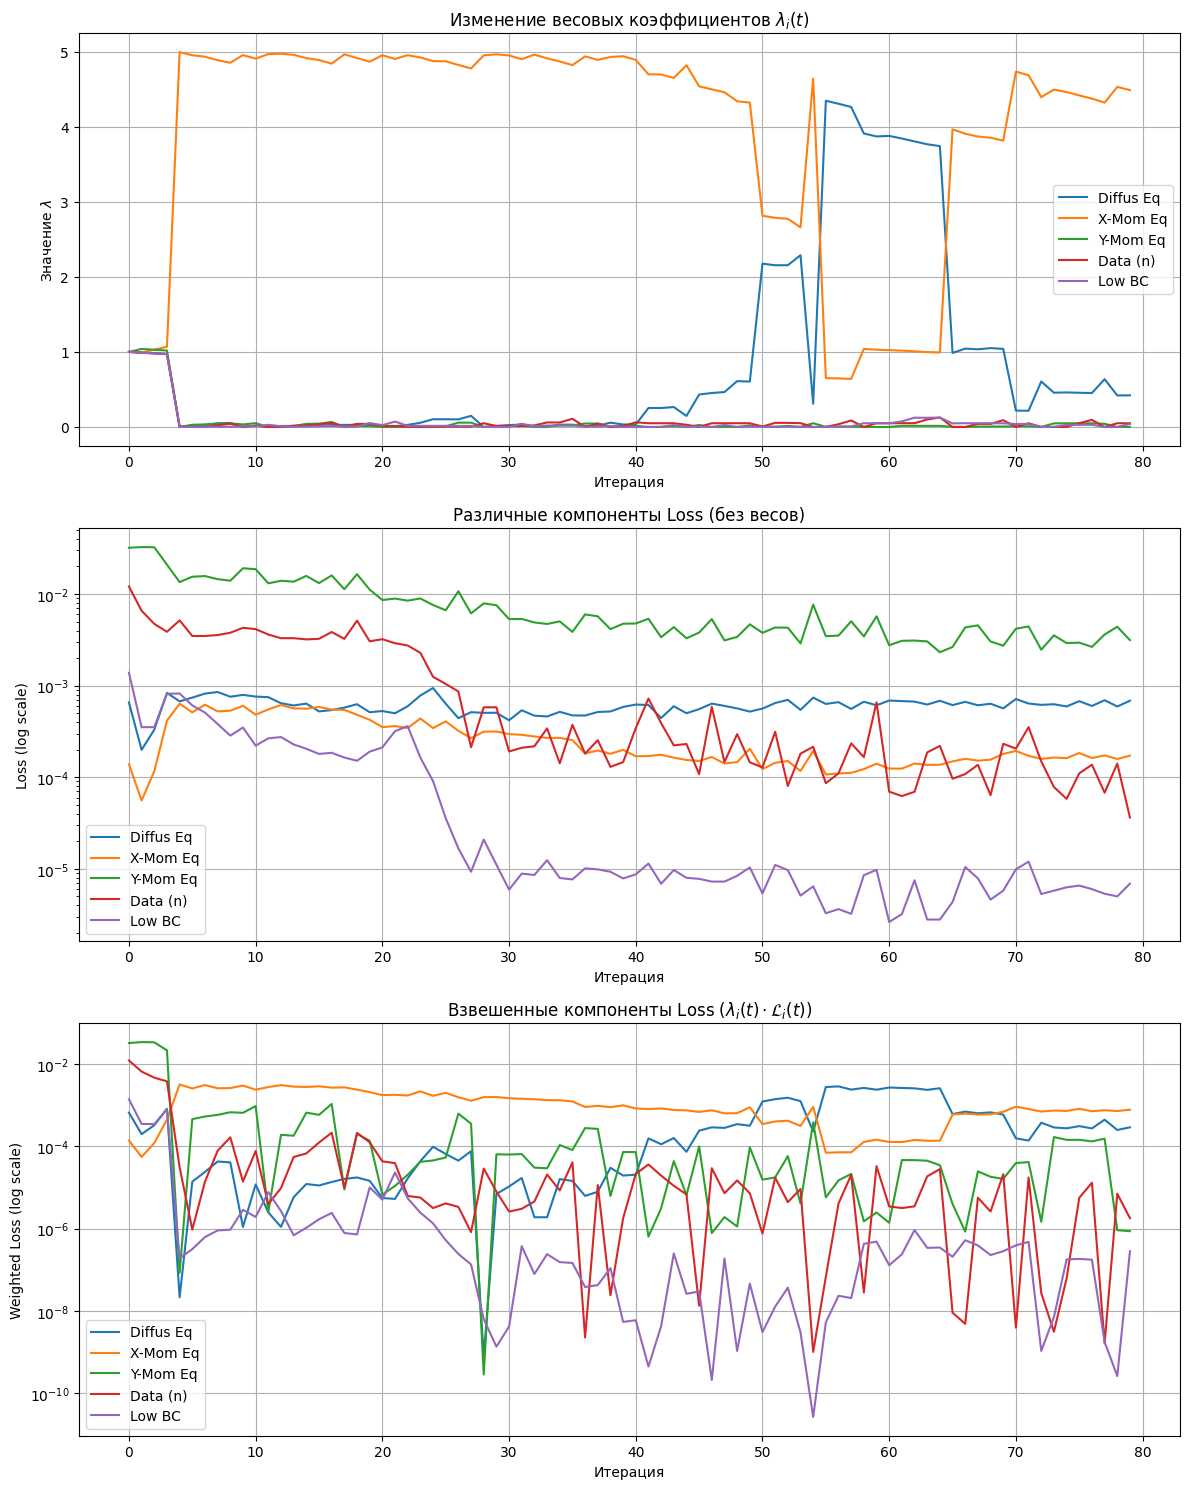

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 15))
iterations = np.arange(num_iterations)

for i in range(num_components):
    axes[0].plot(iterations, lambdas[i], label=loss_names[i])
axes[0].set_title('Изменение весовых коэффициентов $\lambda_i(t)$')
axes[0].set_xlabel('Итерация')
axes[0].set_ylabel('Значение $\lambda$')
axes[0].grid(True)
axes[0].legend()

for i in range(num_components):
    axes[1].plot(iterations, losses_history[i], label=loss_names[i])
axes[1].set_title('Различные компоненты Loss (без весов)')
axes[1].set_xlabel('Итерация')
axes[1].set_ylabel('Loss (log scale)')
axes[1].set_yscale('log')
axes[1].grid(True)
axes[1].legend()

weighted_losses = losses_history * lambdas
for i in range(num_components):
    axes[2].plot(iterations, weighted_losses[i], label=loss_names[i])
axes[2].set_title('Взвешенные компоненты Loss ($\lambda_i(t) \cdot \mathcal{L}_i(t)$)')
axes[2].set_xlabel('Итерация')
axes[2].set_ylabel('Weighted Loss (log scale)')
axes[2].set_yscale('log')
axes[2].grid(True)
axes[2].legend()

plt.tight_layout()
plt.show()